# Градиентный бустинг: визуализации и задания

Семинар 5. Сначала демонстрации для объяснения алгоритма, затем три практических задания.

## Как работать

Запустите настройку и демонстрации А–Г. Затем выполняйте задания; вспомогательные построения уже написаны, ключевые функции помечены `ВАШ КОД`. Неизменённый ноутбук выполняется до конца: незаполненные задания сообщают, что их нужно реализовать, и пропускают зависящие от них расчёты. Другие ошибки не скрываются.

| Раздел | Содержание | Ориентир по времени |
|---|---|---|
| Демонстрации А–Г | Шаг бустинга, градиенты, регуляризация, рост деревьев | В ходе теории |
| 1. Глубина и число деревьев | Подбор GB и сравнение с RF | 25–35 минут |
| 2. Классификация | Собственный градиентный бустинг для log loss | 20–30 минут |
| 3. Три фреймворка | XGBoost, LightGBM, CatBoost: настройка, качество, размер деревьев | 30–45 минут |

Для короткого занятия можно выполнить задания 1 и 3, а реализацию классификатора из задания 2 оставить для самостоятельной работы.

Все данные генерируются локально. Основные зависимости: `numpy`, `matplotlib`, `scipy`, `scikit-learn`, `IPython`, `threadpoolctl`; в задании 3 дополнительно нужны `xgboost`, `lightgbm` и `catboost` из обновлённого `environment.yml`. Устройство библиотек и сводная таблица разобраны в `5. Gradient Boosting — theory.ipynb`. В заданиях 1–2 используем sklearn, в задании 3 — сами три фреймворка. Графики статические и сохраняются в ноутбуке; параметры демонстраций можно менять в вызовах функций.


In [1]:
%matplotlib inline
import html
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from scipy.special import expit
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, GradientBoostingClassifier
from sklearn.datasets import make_friedman1, make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, accuracy_score, roc_auc_score
from IPython.display import display, HTML
from threadpoolctl import threadpool_limits

SEED = 42
BLUE, ORANGE, GREEN, RED = '#2563eb', '#ea580c', '#059669', '#dc2626'
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'figure.dpi': 110})

def table(rows):
    if not rows:
        return
    keys = list(rows[0])
    def fmt(v):
        return f'{v:.4f}' if isinstance(v, (float, np.floating)) else str(v)
    head = ''.join(f'<th>{html.escape(str(k))}</th>' for k in keys)
    body = ''.join('<tr>' + ''.join(f'<td>{html.escape(fmt(row[k]))}</td>' for k in keys) + '</tr>' for row in rows)
    display(HTML('<table><thead><tr>' + head + '</tr></thead><tbody>' + body + '</tbody></table>'))

def rmse(y, pred):
    return float(np.sqrt(mean_squared_error(y, pred)))

def binary_loss(y, score):
    return float(np.mean(np.logaddexp(0., score) - y * score))

def predict_at(model, X, n_trees):
    # staged_predict выдаёт прогноз после 1, 2, ... деревьев.
    if not 1 <= n_trees <= model.n_estimators_:
        raise ValueError('Номер итерации вне диапазона')
    for m, pred in enumerate(model.staged_predict(X), start=1):
        if m == n_trees:
            return pred

print('numpy:', np.__version__, '| sklearn:', sklearn.__version__)
print('Среда готова; загрузка данных из интернета не требуется.')


numpy: 1.26.4 | sklearn: 1.5.1
Среда готова; загрузка данных из интернета не требуется.


## Демонстрация А. Каждое дерево предсказывает поправку

Зависимость из прошлого семинара: $f(x)=\sin(2x)+0.3x$, шум $\sigma=0.35$. Чёрная кривая известна нам как авторам генератора, но недоступна алгоритму.

Слева — ансамбль до шага; в центре — его остатки и новое дерево; справа — прогноз после добавления $\eta h_m$. Дерево в центре показано **до умножения на шаг**. Отрицательные значения — допустимые поправки.

Меняйте `step`, `learning_rate` и `depth` в последней строке. При фиксированном seed данные остаются прежними.


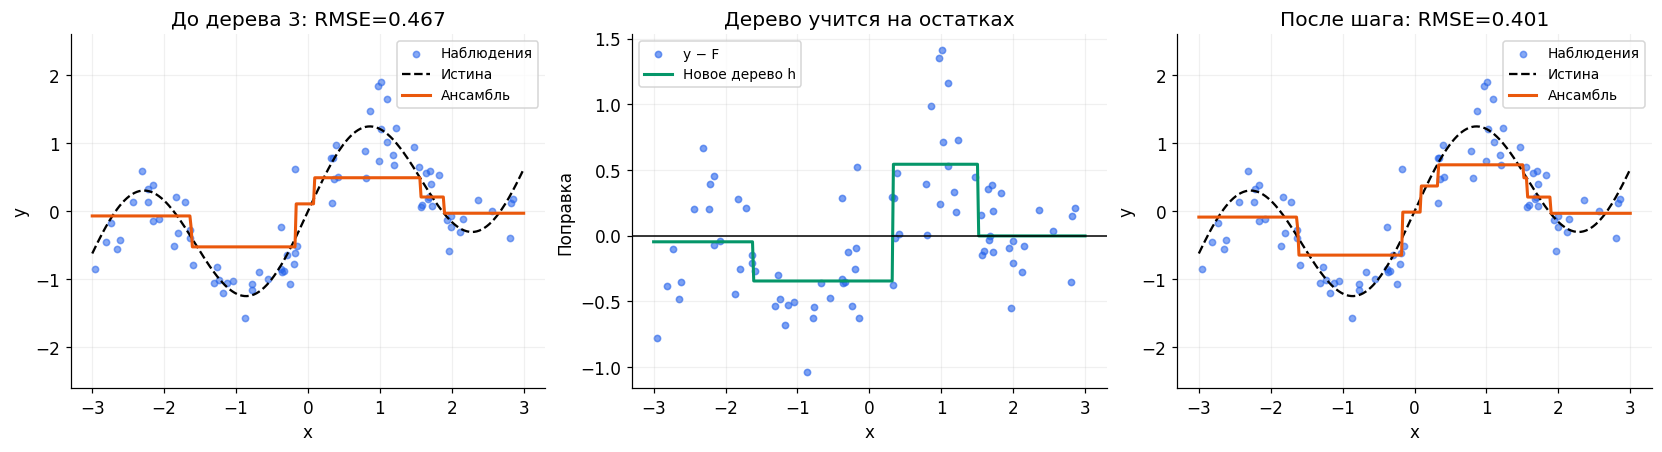

In [2]:
def truth(x):
    return np.sin(2 * x) + .3 * x

rng_demo = np.random.default_rng(SEED)
X_demo = rng_demo.uniform(-3, 3, size=(80, 1))
y_demo = truth(X_demo[:, 0]) + rng_demo.normal(0, .35, len(X_demo))
X_grid = np.linspace(-3, 3, 350)[:, None]

def show_boost_step(step=3, learning_rate=.35, depth=2):
    if step < 1:
        raise ValueError('step >= 1')
    train_pred = np.full(len(y_demo), y_demo.mean())
    grid_pred = np.full(len(X_grid), y_demo.mean())
    for m in range(1, step + 1):
        before_train, before_grid = train_pred.copy(), grid_pred.copy()
        residual = y_demo - before_train
        tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=3, random_state=SEED + m)
        tree.fit(X_demo, residual)
        correction = tree.predict(X_grid)
        train_pred += learning_rate * tree.predict(X_demo)
        grid_pred += learning_rate * correction
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for ax in axes[[0, 2]]:
        ax.scatter(X_demo[:, 0], y_demo, s=17, alpha=.55, color=BLUE, label='Наблюдения')
        ax.plot(X_grid[:, 0], truth(X_grid[:, 0]), 'k--', lw=1.5, label='Истина')
        ax.set(xlabel='x', ylabel='y', ylim=(-2.6, 2.6))
    axes[0].plot(X_grid[:, 0], before_grid, color=ORANGE, lw=2, label='Ансамбль')
    axes[0].set_title(f'До дерева {step}: RMSE={rmse(y_demo, before_train):.3f}')
    axes[1].scatter(X_demo[:, 0], residual, s=17, alpha=.6, color=BLUE, label='y − F')
    axes[1].plot(X_grid[:, 0], correction, color=GREEN, lw=2, label='Новое дерево h')
    axes[1].axhline(0, color='black', lw=1)
    axes[1].set(xlabel='x', ylabel='Поправка', title='Дерево учится на остатках')
    axes[2].plot(X_grid[:, 0], grid_pred, color=ORANGE, lw=2, label='Ансамбль')
    axes[2].set_title(f'После шага: RMSE={rmse(y_demo, train_pred):.3f}')
    for ax in axes:
        ax.legend(fontsize=9)
    plt.show()

show_boost_step(step=3, learning_rate=.35, depth=2)


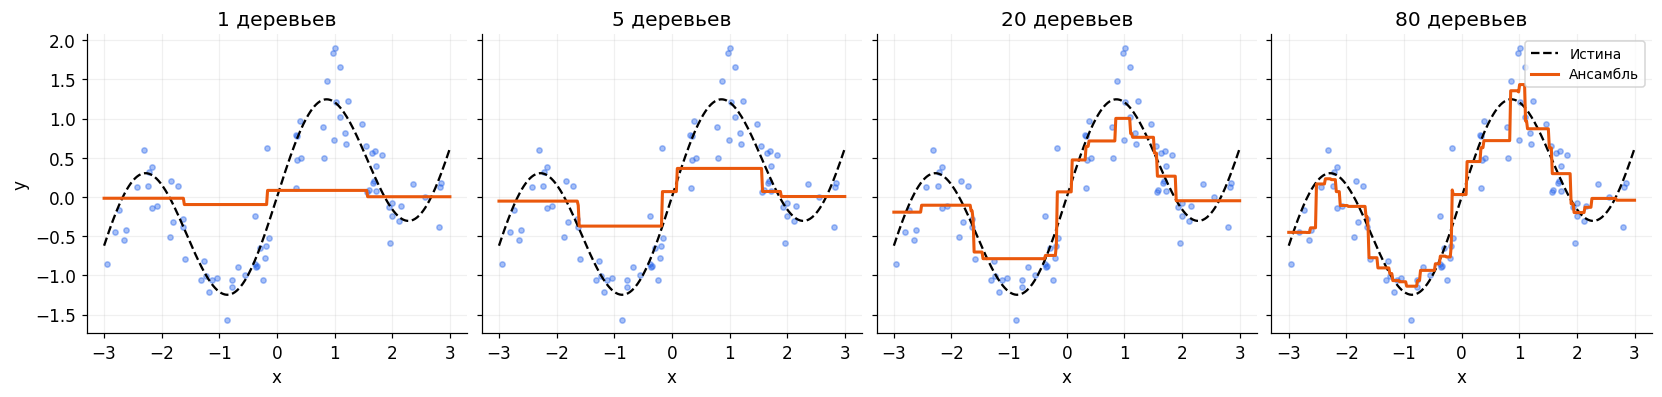

In [3]:
demo_model = GradientBoostingRegressor(n_estimators=80, learning_rate=.1, max_depth=2,
                                     min_samples_leaf=3, random_state=SEED).fit(X_demo, y_demo)
snapshots = {m: p.copy() for m, p in enumerate(demo_model.staged_predict(X_grid), 1) if m in [1, 5, 20, 80]}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True, constrained_layout=True)
for ax, (m, pred) in zip(axes, snapshots.items()):
    ax.scatter(X_demo[:, 0], y_demo, s=12, alpha=.4, color=BLUE)
    ax.plot(X_grid[:, 0], truth(X_grid[:, 0]), 'k--', label='Истина')
    ax.plot(X_grid[:, 0], pred, color=ORANGE, lw=2, label='Ансамбль')
    ax.set(title=f'{m} деревьев', xlabel='x')
axes[0].set_ylabel('y')
axes[-1].legend(fontsize=9)
plt.show()


**Обсудить:** уменьшается ли шаг самой модели при добавлении деревьев? Обязано ли уменьшение train loss означать улучшение на новых объектах? Может ли ансамбль ступенчатых функций стать непрерывным? Для конечного числа обычных регрессионных деревьев прогноз остаётся кусочно-постоянным; на масштабе картинки ступеньки могут быть мелкими.

## Демонстрация Б. Разные потери — разные цели дерева

Для $\frac12(y-F)^2$ цель равна $y-F$; для бинарной log loss с логитом $F$ — $y-\sigma(F)$. На правой панели потеря положительного объекта уменьшается и после того, как класс уже стал правильным. Это не обещание, что уверенность всегда полезно наращивать на validation.


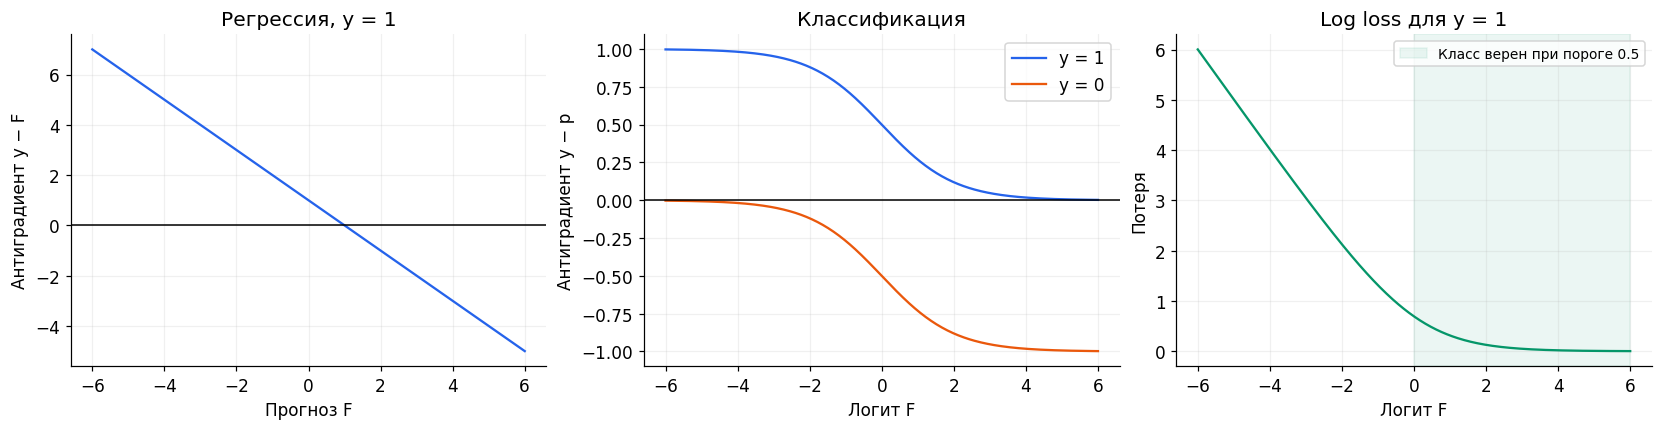

In [4]:
score_axis = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
axes[0].plot(score_axis, 1 - score_axis, color=BLUE)
axes[0].axhline(0, color='black', lw=1)
axes[0].set(title='Регрессия, y = 1', xlabel='Прогноз F', ylabel='Антиградиент y − F')
axes[1].plot(score_axis, 1 - expit(score_axis), color=BLUE, label='y = 1')
axes[1].plot(score_axis, -expit(score_axis), color=ORANGE, label='y = 0')
axes[1].axhline(0, color='black', lw=1)
axes[1].set(title='Классификация', xlabel='Логит F', ylabel='Антиградиент y − p')
axes[1].legend()
axes[2].plot(score_axis, np.logaddexp(0, score_axis) - score_axis, color=GREEN)
axes[2].axvspan(0, 6, color=GREEN, alpha=.08, label='Класс верен при пороге 0.5')
axes[2].set(title='Log loss для y = 1', xlabel='Логит F', ylabel='Потеря')
axes[2].legend(fontsize=9)
plt.show()


## Демонстрация В. Регуляризация значения листа

Квадратичное приближение в одном листе: $Q(w)=Gw+\frac12(H+\lambda)w^2$; минимум $w^*=-G/(H+\lambda)$.

Слева меняем штраф при фиксированных $G=-3,H=1$. Справа показано относительное сжатие $w_\lambda/w_0=H/(H+\lambda)$: одинаковая $\lambda$ сильнее сжимает лист с меньшим $H$. Это иллюстрация одного шага, а не доказательство улучшения test loss.


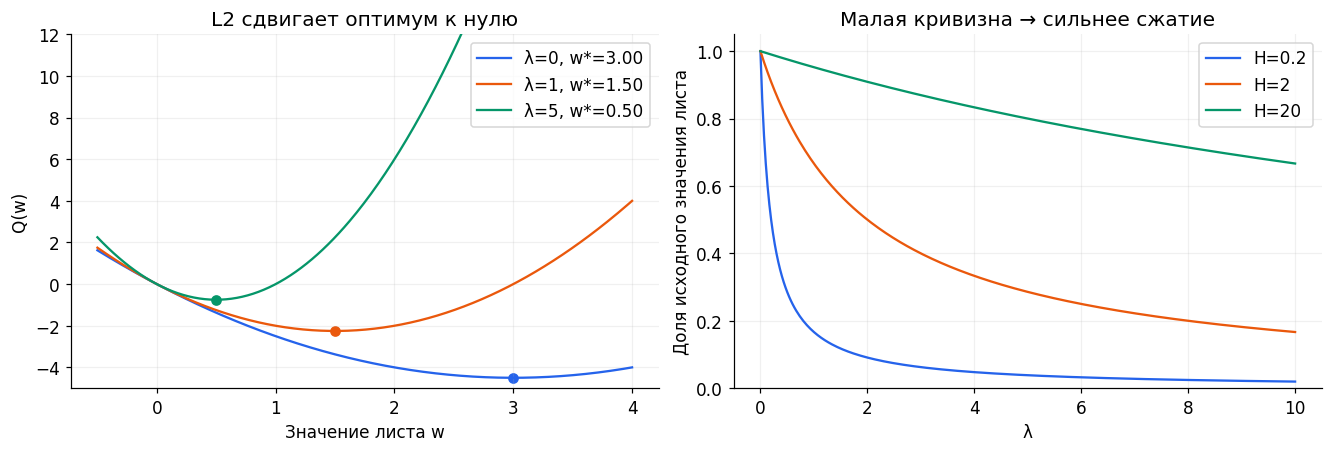

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
w_axis = np.linspace(-.5, 4, 300)
for lam, color in zip([0, 1, 5], [BLUE, ORANGE, GREEN]):
    q = -3 * w_axis + .5 * (1 + lam) * w_axis**2
    optimum = 3 / (1 + lam)
    axes[0].plot(w_axis, q, color=color, label=f'λ={lam}, w*={optimum:.2f}')
    axes[0].scatter([optimum], [-3 * optimum + .5 * (1 + lam) * optimum**2], color=color)
axes[0].set(xlabel='Значение листа w', ylabel='Q(w)', title='L2 сдвигает оптимум к нулю', ylim=(-5, 12))
lam_axis = np.linspace(0, 10, 300)
for h, color in zip([.2, 2, 20], [BLUE, ORANGE, GREEN]):
    axes[1].plot(lam_axis, h / (h + lam_axis), color=color, label=f'H={h}')
axes[1].set(xlabel='λ', ylabel='Доля исходного значения листа', title='Малая кривизна → сильнее сжатие', ylim=(0, 1.05))
for ax in axes:
    ax.legend()
plt.show()


## Демонстрация Г. Три способа построения дерева

Это **схемы**, не деревья из обученных библиотек. У первых двух деревьев по четыре листа, но максимальная глубина разная. При послойном росте условия узлов одного уровня могут различаться; в симметричном дереве они одинаковы. Порядок роста — выбор того, какой узел расширять следующим, а не функция потерь.

LightGBM использует leaf-wise. XGBoost поддерживает разные политики, включая depthwise/lossguide. CatBoost поддерживает SymmetricTree и другие политики. Схема не делит библиотеки на непересекающиеся классы.


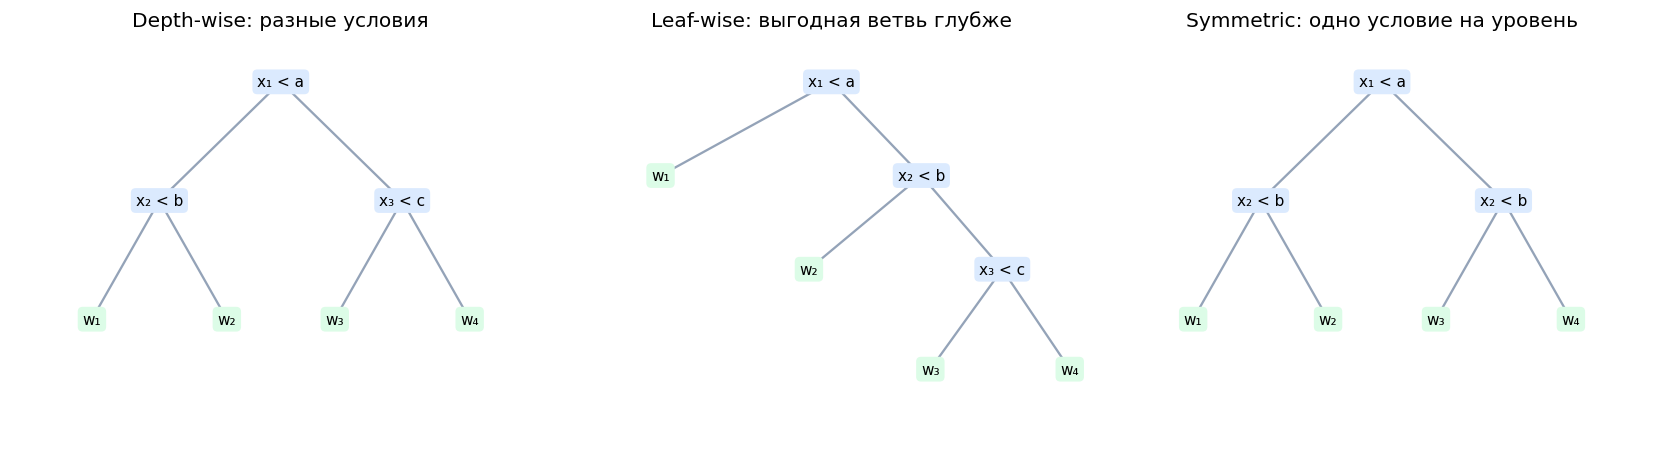

In [6]:
def draw_tree_scheme(ax, nodes, edges, title):
    for parent, child in edges:
        x0, y0, _ = nodes[parent]
        x1, y1, _ = nodes[child]
        ax.plot([x0, x1], [y0, y1], color='#94a3b8', zorder=1)
    parents = {p for p, _ in edges}
    for key, (x, y, label) in nodes.items():
        ax.text(x, y, label, ha='center', va='center', fontsize=10,
                bbox={'boxstyle': 'round,pad=.32', 'fc': '#dbeafe' if key in parents else '#dcfce7', 'ec': 'none'}, zorder=2)
    ax.set(xlim=(-.1, 1.1), ylim=(-.15, 1.15), title=title)
    ax.axis('off')

balanced = {'r': (.5, 1, 'x₁ < a'), 'l': (.23, .62, 'x₂ < b'), 'q': (.77, .62, 'x₃ < c'),
            'a': (.08, .24, 'w₁'), 'b': (.38, .24, 'w₂'), 'c': (.62, .24, 'w₃'), 'd': (.92, .24, 'w₄')}
edges_bal = [('r', 'l'), ('r', 'q'), ('l', 'a'), ('l', 'b'), ('q', 'c'), ('q', 'd')]
leafwise = {'r': (.5, 1, 'x₁ < a'), 'a': (.12, .7, 'w₁'), 'q': (.7, .7, 'x₂ < b'),
            'b': (.45, .4, 'w₂'), 's': (.88, .4, 'x₃ < c'), 'c': (.72, .08, 'w₃'), 'd': (1.03, .08, 'w₄')}
edges_leaf = [('r', 'a'), ('r', 'q'), ('q', 'b'), ('q', 's'), ('s', 'c'), ('s', 'd')]
symmetric = dict(balanced)
symmetric['q'] = (.77, .62, 'x₂ < b')
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
draw_tree_scheme(axes[0], balanced, edges_bal, 'Depth-wise: разные условия')
draw_tree_scheme(axes[1], leafwise, edges_leaf, 'Leaf-wise: выгодная ветвь глубже')
draw_tree_scheme(axes[2], symmetric, edges_bal, 'Symmetric: одно условие на уровень')
plt.show()


## 1. Подобрать глубину, шаг и число деревьев

**Гипотеза до запуска:** для леса глубокие деревья часто полезнее, чем для бустинга. Проверим это на одной задаче, а не будем зашивать вывод в правило.

Данные: $y=10\sin(\pi x_1x_2)+20(x_3-0.5)^2+10x_4+5x_5+\varepsilon$, десять признаков, из них пять шумовых, $\sigma_\varepsilon=2.5$.

Протокол: 500 train, 300 validation, 300 test. Метрика RMSE. Все модели получают один train. Для RF сравниваем глубины при фиксированных 160 деревьях, `min_samples_leaf=2`, `max_features=0.7`. Для GB — те же глубины, три шага и до 300 итераций; лучшую итерацию выбираем по validation. Это ограниченный поиск, не равные вычислительные бюджеты и не соревнование всех возможных настроек.

### 1.1. Реализуйте три функции

- `make_boost(depth, learning_rate, n_estimators, seed)` — необученный `GradientBoostingRegressor`, квадратичная потеря, `min_samples_leaf=2`, без встроенной ранней остановки.
- `choose_stage(predictions, y)` — получить последовательность прогнозов после 1, 2, … деревьев; вернуть `(best_m, errors)`, где `best_m` начинается с **1**, `errors` — массив RMSE. При равенстве выбрать первый минимум.
- `choose_run(results)` — вернуть строку с наименьшим `val_rmse`, не обращаясь к test. При равенстве — первую.

Перед запуском запишите ожидаемые лучшие глубины для RF и GB: …


In [7]:
X_all, y_all = make_friedman1(n_samples=1100, n_features=10, noise=2.5, random_state=2026)
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=300, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=300, random_state=SEED)
DEPTHS, RATES, MAX_TREES = [1, 2, 3, 6, None], [.03, .1, .3], 300
print('Train / validation / test:', len(y_train), len(y_val), len(y_test))


Train / validation / test: 500 300 300


In [8]:
def make_boost(depth, learning_rate, n_estimators=MAX_TREES, seed=SEED):
    # ВАШ КОД: вернуть необученную модель с заданными параметрами.
    raise NotImplementedError('Реализуйте make_boost')

def choose_stage(predictions, y):
    # ВАШ КОД: массив RMSE, первый минимум, номер итерации с единицы.
    raise NotImplementedError('Реализуйте choose_stage')

def choose_run(results):
    # ВАШ КОД: выбор только по val_rmse.
    raise NotImplementedError('Реализуйте choose_run')


In [9]:
search_ready = False
try:
    m, errors = choose_stage(iter([np.array([1., 3.]), np.array([0., 2.]), np.array([0., 2.])]), np.array([0., 2.]))
    assert m == 2 and np.allclose(errors, [1, 0, 0]), 'Проверьте нумерацию и первый минимум'
    sentinel = [{'val_rmse': 2., 'test_rmse': 0.}, {'val_rmse': 1., 'test_rmse': 10.}]
    assert choose_run(sentinel) is sentinel[1], 'Test не участвует в выборе'
    demo = make_boost(2, .1, n_estimators=3, seed=7)
    assert demo.max_depth == 2 and demo.n_estimators == 3 and demo.random_state == 7
    search_ready = True
except NotImplementedError as exc:
    print(exc)

gb_results, rf_results, selected_gb, selected_rf = [], [], None, None
if search_ready:
    with threadpool_limits(limits=1):
        for depth in DEPTHS:
            forest = RandomForestRegressor(n_estimators=160, max_depth=depth, min_samples_leaf=2,
                                           max_features=.7, n_jobs=1, random_state=SEED).fit(X_train, y_train)
            rf_results.append({'depth': depth, 'train_rmse': rmse(y_train, forest.predict(X_train)),
                               'val_rmse': rmse(y_val, forest.predict(X_val)), 'model': forest})
            for rate in RATES:
                model = make_boost(depth, rate).fit(X_train, y_train)
                best_m, val_curve = choose_stage(model.staged_predict(X_val), y_val)
                train_curve = np.array([rmse(y_train, p) for p in model.staged_predict(X_train)])
                gb_results.append({'depth': depth, 'rate': rate, 'best_m': best_m,
                                   'train_rmse': train_curve[best_m - 1], 'val_rmse': val_curve[best_m - 1],
                                   'train_curve': train_curve, 'val_curve': val_curve, 'model': model})
    selected_gb, selected_rf = choose_run(gb_results), choose_run(rf_results)
    table([{'Модель': 'RF', 'Глубина': str(r['depth']), 'Шаг': '—', 'Деревьев': 160,
            'Train RMSE': r['train_rmse'], 'Val RMSE': r['val_rmse']} for r in rf_results])
    table([{'Модель': 'GB', 'Глубина': str(r['depth']), 'Шаг': r['rate'], 'Лучшая итерация': r['best_m'],
            'Train RMSE': r['train_rmse'], 'Val RMSE': r['val_rmse']} for r in gb_results])


Реализуйте choose_stage


In [10]:
if search_ready:
    matrix = np.array([[next(r['val_rmse'] for r in gb_results if r['depth'] == d and r['rate'] == lr)
                        for d in DEPTHS] for lr in RATES])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
    im = axes[0].imshow(matrix, aspect='auto', cmap='YlGnBu_r')
    axes[0].set(xticks=range(len(DEPTHS)), xticklabels=[str(d) for d in DEPTHS],
                yticks=range(len(RATES)), yticklabels=RATES, xlabel='max_depth', ylabel='learning_rate',
                title='GB: лучший validation RMSE по итерациям')
    for i in range(len(RATES)):
        for j in range(len(DEPTHS)):
            axes[0].text(j, i, f'{matrix[i,j]:.2f}', ha='center', va='center',
                         color='white' if matrix[i,j] < (matrix.min()+matrix.max())/2 else '#111827')
    fig.colorbar(im, ax=axes[0], label='RMSE')
    axes[1].plot(range(len(DEPTHS)), [r['val_rmse'] for r in rf_results], 'o-', label='RF: 160 деревьев', color=BLUE)
    axes[1].plot(range(len(DEPTHS)), matrix.min(axis=0), 'o-', label='GB: выбран шаг и итерация', color=ORANGE)
    axes[1].set(xticks=range(len(DEPTHS)), xticklabels=[str(d) for d in DEPTHS],
                xlabel='max_depth', ylabel='Validation RMSE', title='Чувствительность к глубине')
    axes[1].legend(fontsize=9)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    for depth in [1, 3, None]:
        r = next(r for r in gb_results if r['depth'] == depth and r['rate'] == .1)
        line, = axes[0].plot(np.arange(1, MAX_TREES+1), r['val_curve'], label=f'depth={depth}, validation')
        axes[0].plot(np.arange(1, MAX_TREES+1), r['train_curve'], '--', color=line.get_color(), alpha=.7)
    for rate in RATES:
        r = next(r for r in gb_results if r['depth'] == selected_gb['depth'] and r['rate'] == rate)
        axes[1].plot(np.arange(1, MAX_TREES+1), r['val_curve'], label=f'η={rate}, best={r["best_m"]}')
        axes[1].scatter([r['best_m']], [r['val_rmse']], s=30)
    axes[0].set(title='Глубина: сплошная val, пунктир train', xlabel='Число деревьев', ylabel='RMSE')
    axes[1].set(title=f'Шаг при depth={selected_gb["depth"]}', xlabel='Число деревьев', ylabel='Validation RMSE')
    for ax in axes:
        ax.legend(fontsize=9)
    plt.show()


### 1.2. Когда мы бы остановились онлайн?

Мы уже обучили полные ансамбли: `best_m` — ретроспективный минимум, а не сэкономленное время. Готовая функция ниже имитирует чтение кривой слева направо: остановиться после 25 шагов без улучшения хотя бы на `1e-3`, вернуть лучшую **увиденную** итерацию. Последующие значения она не рассматривает.

Сравните stop, best_seen и минимум всей кривой. Если остановка не сработала до бюджета, возвращается последний доступный шаг. Небольшой поздний спад полной кривой ещё не означает, что разумно было ждать его в реальной работе.


In [11]:
def simulate_early_stopping(curve, patience=25, min_delta=1e-3):
    if len(curve) == 0 or patience < 1 or min_delta < 0:
        raise ValueError('Проверьте аргументы')
    anchor, wait, best_seen = np.inf, 0, 1
    for m, error in enumerate(curve, 1):
        if error < curve[best_seen - 1]:
            best_seen = m
        if error < anchor - min_delta:
            anchor, wait = error, 0
        else:
            wait += 1
        if wait >= patience:
            return m, best_seen
    return len(curve), best_seen

if search_ready:
    rows = []
    for rate in RATES:
        r = next(r for r in gb_results if r['depth'] == 3 and r['rate'] == rate)
        stop, seen = simulate_early_stopping(r['val_curve'])
        rows.append({'Шаг': rate, 'Остановка': stop, 'Лучшая увиденная': seen,
                     'Минимум полной кривой': r['best_m']})
    table(rows)


### 1.3. Финальная оценка

Сначала зафиксируйте выбранные параметры и объясните выбор. Затем разрешите оценку test. Для GB используем прогноз **выбранного префикса**, а не всех 300 деревьев. Обе модели по-прежнему обучены только на train.

Вопросы:

1. Совпали ли оптимальные глубины RF и GB? Насколько результат зависит от рассмотренной сетки?
2. Какая модель быстрее уменьшает train loss и почему это не окончательный критерий?
3. Если при маленьком шаге лучшая итерация равна 300, что это говорит о бюджете поиска?
4. Можно ли на основании этого опыта утверждать, что GB всегда лучше RF или всегда требует глубину 3?
5. Какие виды регуляризации мы меняли, а какие оставили фиксированными?

**Ваши выводы:** …


In [12]:
EVALUATE_TEST = False  # Поставьте True после фиксации параметров.


In [13]:
if EVALUATE_TEST and search_ready:
    table([{'Модель': 'Константа train', 'Test RMSE': rmse(y_test, np.full(len(y_test), y_train.mean()))},
           {'Модель': f'RF depth={selected_rf["depth"]}', 'Test RMSE': rmse(y_test, selected_rf['model'].predict(X_test))},
           {'Модель': f'GB depth={selected_gb["depth"]}, η={selected_gb["rate"]}, M={selected_gb["best_m"]}',
            'Test RMSE': rmse(y_test, predict_at(selected_gb['model'], X_test, selected_gb['best_m']))}])
else:
    print('Test пока закрыт: сначала выполните подбор и зафиксируйте параметры.')


Test пока закрыт: сначала выполните подбор и зафиксируйте параметры.


## 2. Собрать градиентный бустинг для классификации

Будем предсказывать **логит** $F$; вероятность $p=\sigma(F)$, антиградиент log loss — $y-p$.

Реализуйте:

1. `negative_gradient(y, score)` — антиградиент по логиту, массив той же формы.
2. `fit_logistic_boost(...)` — начальный логит по доле положительного класса, цикл обучения `DecisionTreeRegressor` на антиградиентах и обновление **суммы логитов**. Вернуть словарь `{'init': число, 'rate': число, 'trees': список}`.

Начальную долю ограничьте диапазоном `[1e-6, 1-1e-6]`. У деревьев задайте `min_samples_leaf=8`, `random_state=seed+m`, где `m` начинается с нуля. Подвыборки не нужны. Предсказание и визуализации готовы.

Это намеренно простой **градиентный** вариант: средние антиградиентов в листьях без ньютоновского пересчёта. Он не обязан совпадать с `GradientBoostingClassifier`, XGBoost или CatBoost по числу шагов и прогнозам.


In [14]:
def negative_gradient(y, score):
    # ВАШ КОД: производная берётся по логиту, не по вероятности.
    raise NotImplementedError('Реализуйте negative_gradient')

def fit_logistic_boost(X, y, n_estimators=250, learning_rate=.5, depth=3, seed=SEED):
    # ВАШ КОД: F0, остатки, дерево, обновление score, сохранение деревьев.
    raise NotImplementedError('Реализуйте fit_logistic_boost')


In [15]:
def raw_predict(model, X, n_trees=None):
    n_trees = len(model['trees']) if n_trees is None else n_trees
    if not 0 <= n_trees <= len(model['trees']):
        raise ValueError('Проверьте число деревьев')
    score = np.full(len(X), model['init'])
    for tree in model['trees'][:n_trees]:
        score += model['rate'] * tree.predict(X)
    return score

def score_history(model, X):
    score = np.full(len(X), model['init'])
    yield score.copy()  # В этом задании история включает M=0.
    for tree in model['trees']:
        score += model['rate'] * tree.predict(X)
        yield score.copy()

classification_ready = False
try:
    labels = np.array([0., 1., 1., 0.])
    scores = np.array([-2., -.3, 1., 3.])
    eps = 1e-5
    plus = np.logaddexp(0., scores + eps) - labels * (scores + eps)
    minus = np.logaddexp(0., scores - eps) - labels * (scores - eps)
    assert np.allclose(negative_gradient(labels, scores), -(plus-minus)/(2*eps), atol=1e-7)
    assert np.all(np.isfinite(negative_gradient(np.array([0., 1.]), np.array([-1000., 1000.]))))
    X_check = np.arange(40.)[:, None]
    y_check = (X_check[:, 0] >= 30).astype(float)
    init_check = np.log(.25/.75)
    one_step = fit_logistic_boost(X_check, y_check, n_estimators=1, learning_rate=.3, depth=1, seed=8)
    assert np.isclose(one_step['init'], init_check) and len(one_step['trees']) == 1
    expected_tree = DecisionTreeRegressor(max_depth=1, min_samples_leaf=8, random_state=8).fit(X_check, y_check-.25)
    expected_score = init_check + .3 * expected_tree.predict(X_check)
    assert np.allclose(raw_predict(one_step, X_check), expected_score), 'Обновлять нужно логит'
    assert binary_loss(y_check, expected_score) < binary_loss(y_check, np.full(len(y_check), init_check))
    classification_ready = True
    print('Производная, устойчивость и первый шаг проверены.')
except NotImplementedError as exc:
    print(exc)


Реализуйте negative_gradient


### 2.1. Правильные классы и хорошие вероятности

Две «луны», шум в признаках; каждая метка независимо переворачивается с вероятностью 8%. Train/validation имеют один механизм генерации. Здесь validation используется для учебного анализа траектории; это не финальная независимая оценка выбранного классификатора.

До запуска предположите: будут ли лучшие итерации по accuracy и log loss совпадать? Построим обе метрики и посмотрим на вероятности на плоскости. На картах используем одинаковую цветовую шкалу `[0,1]`.


In [16]:
X_cls, y_cls = make_moons(n_samples=800, noise=.28, random_state=2027)
rng_cls = np.random.default_rng(2027)
flip = rng_cls.random(len(y_cls)) < .08
y_cls[flip] = 1 - y_cls[flip]
Xc_train, Xc_val, yc_train, yc_val = train_test_split(X_cls, y_cls, train_size=300,
                                                   random_state=SEED, stratify=y_cls)
classification_model = None
if classification_ready:
    classification_model = fit_logistic_boost(Xc_train, yc_train)
    train_scores = np.array(list(score_history(classification_model, Xc_train)))
    val_scores = np.array(list(score_history(classification_model, Xc_val)))
    train_losses = np.array([binary_loss(yc_train, s) for s in train_scores])
    val_losses = np.array([binary_loss(yc_val, s) for s in val_scores])
    val_accuracy = np.array([accuracy_score(yc_val, s >= 0) for s in val_scores])
    train_accuracy = np.array([accuracy_score(yc_train, s >= 0) for s in train_scores])
    best_loss_m, best_accuracy_m = int(np.argmin(val_losses)), int(np.argmax(val_accuracy))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    axes[0].plot(train_losses, '--', color=BLUE, label='Train')
    axes[0].plot(val_losses, color=ORANGE, label='Validation')
    axes[0].axvline(best_loss_m, color=GREEN, ls=':', label=f'Best log loss: {best_loss_m}')
    axes[0].set(xlabel='Число деревьев (включая 0)', ylabel='Log loss', title='Цена уверенности')
    axes[1].plot(train_accuracy, '--', color=BLUE, label='Train')
    axes[1].plot(val_accuracy, color=ORANGE, label='Validation')
    axes[1].axvline(best_accuracy_m, color=GREEN, ls=':', label=f'Best accuracy: {best_accuracy_m}')
    axes[1].set(xlabel='Число деревьев', ylabel='Accuracy при пороге 0.5', title='Классы меняются дискретно')
    for ax in axes:
        ax.legend(fontsize=9)
    plt.show()
    table([{'Итерация': m, 'Val log loss': val_losses[m], 'Val accuracy': val_accuracy[m]}
           for m in sorted(set([0, best_loss_m, best_accuracy_m, len(classification_model['trees'])]))])

    gx, gy = np.meshgrid(np.linspace(-1.8, 2.8, 150), np.linspace(-1.3, 1.9, 120))
    grid_cls = np.c_[gx.ravel(), gy.ravel()]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    for ax, m in zip(axes, [1, 30, len(classification_model['trees'])]):
        probability = expit(raw_predict(classification_model, grid_cls, m)).reshape(gx.shape)
        im = ax.contourf(gx, gy, probability, levels=np.linspace(0, 1, 21), cmap='RdBu_r', vmin=0, vmax=1)
        ax.scatter(Xc_val[:, 0], Xc_val[:, 1], c=yc_val, cmap='RdBu_r', vmin=0, vmax=1,
                   edgecolors='white', linewidths=.4, s=13, alpha=.65)
        ax.set(title=f'{m} деревьев; точки validation', xlabel='x₁', ylabel='x₂')
    fig.colorbar(im, ax=axes, label='P(y=1)')
    plt.show()


### 2.2. Отделить accuracy от уверенности

Зафиксируем прогнозы выбранного по log loss ансамбля. Умножение логита на положительное число сохраняет знак, значит при пороге 0.5 сохраняет классы. Но вероятности и log loss меняются. Это **диагностический опыт**, не подбор калибровки на test.

Объясните, почему при масштабе 4 правильные ответы могут стать «лучше», а ошибочные — существенно дороже. Низкая log loss сама по себе не доказывает идеальную калибровку вероятностей.


In [17]:
if classification_ready:
    chosen_score = val_scores[best_loss_m]
    table([{'Множитель логита': scale, 'Accuracy': accuracy_score(yc_val, scale*chosen_score >= 0),
            'Log loss': binary_loss(yc_val, scale*chosen_score),
            'Средняя уверенность': float(np.mean(np.maximum(expit(scale*chosen_score), 1-expit(scale*chosen_score))))}
           for scale in [.25, 1., 4.]])


## 3. XGBoost, LightGBM и CatBoost на одной задаче

В теории мы обсудили, как библиотеки строят деревья и управляют сложностью. Теперь обучим настоящие модели трёх фреймворков и посмотрим, как различия отражаются в результатах.

Нужно собрать небольшой сравнительный эксперимент: выбрать лучшую конфигурацию **внутри каждой библиотеки**, сравнить траектории обучения и размер деревьев, затем оценить три выбранные модели на независимом test.

### 3.1. Данные и правила сравнения

Используем новую выборку Friedman с десятью численными признаками и шумом $\sigma=2$: 1500 объектов train, 500 validation и 500 test. Разбиение общее для всех библиотек и отличается от задания 1. Целевая метрика — RMSE. Категориальных признаков здесь нет: этот эксперимент сравнивает численные деревья и их регуляризацию; преимущества обработки категорий из него вывести нельзя.

Зафиксируем шаг 0.05, максимум 400 итераций и остановку после 30 итераций без улучшения validation RMSE. Для каждой библиотеки проверим шесть конфигураций: два ограничения сложности × три значения L2. Обучаем на CPU с одним потоком, чтобы не смешивать настройки параллелизма.

| Библиотека | Два ограничения сложности | Три значения L2 |
|---|---|---|
| XGBoost | `max_depth`: 3, 6 | `reg_lambda`: 0, 3, 10 |
| LightGBM | `num_leaves`: 7, 31 | `reg_lambda`: 0, 3, 10 |
| CatBoost | `depth`: 3, 6 | `l2_leaf_reg`: 0, 3, 10 |

Это одинаковое число проверяемых конфигураций и общий предел итераций, но не одинаковое семейство моделей и не равное вычислительное время. Значение L2=3 имеет разный контекст в разных реализациях. Случайные подвыборки в этом опыте отключаем; CatBoost явно запускаем в `Plain` с `SymmetricTree`.

До запуска запишите гипотезы: как изменятся качество, число итераций и время при увеличении сложности? Обязана ли модель с минимальной ошибкой быть самой быстрой? …


### Подготовка библиотек

В `environment.yml` добавлены LightGBM и CatBoost; XGBoost уже входил в среду курса. Из корня проекта можно обновить её командой `conda env update -f environment.yml`, затем выбрать соответствующее ядро Jupyter.

Для отдельной pip-среды используйте в ячейке `%pip install "xgboost>=2,<4" "lightgbm>=4,<5" "catboost>=1.2,<2"` и перезапустите ядро. Установка требует интернета; дальнейшее обучение использует только локальные синтетические данные. При ошибке загрузки OpenMP используйте среду conda-forge из проекта, где системные зависимости разрешаются вместе с пакетами.

Следующая ячейка проверяет импорты и печатает версии. Если пакеты не установлены, только задание 3 будет пропущено до подготовки среды; задания 1–2 остаются доступны.


In [18]:
from importlib import import_module
from itertools import product
from time import perf_counter

framework_modules, framework_import_errors = {}, {}
for package in ['xgboost', 'lightgbm', 'catboost']:
    try:
        framework_modules[package] = import_module(package)
    except (ImportError, OSError) as exc:
        framework_import_errors[package] = str(exc)

frameworks_available = not framework_import_errors
if frameworks_available:
    xgb, lgb, cb = [framework_modules[name] for name in ['xgboost', 'lightgbm', 'catboost']]
    table([{'Библиотека': name, 'Версия': module.__version__} for name, module in framework_modules.items()])
else:
    for name, error in framework_import_errors.items():
        print(f'{name}: {error}')
    print('Подготовьте среду, перезапустите ядро и выполните ноутбук заново.')

FRAMEWORKS = ['XGBoost', 'LightGBM', 'CatBoost']
FRAMEWORK_ROUNDS, FRAMEWORK_RATE, FRAMEWORK_PATIENCE = 400, .05, 30
framework_grid = {
    'XGBoost': [{'max_depth': depth, 'reg_lambda': penalty} for depth, penalty in product([3, 6], [0., 3., 10.])],
    'LightGBM': [{'num_leaves': leaves, 'reg_lambda': penalty} for leaves, penalty in product([7, 31], [0., 3., 10.])],
    'CatBoost': [{'depth': depth, 'l2_leaf_reg': penalty} for depth, penalty in product([3, 6], [0., 3., 10.])],
}

Xf_all, yf_all = make_friedman1(n_samples=2500, n_features=10, noise=2., random_state=509)
Xf_dev, Xf_test, yf_dev, yf_test = train_test_split(Xf_all, yf_all, test_size=500, random_state=509)
Xf_train, Xf_val, yf_train, yf_val = train_test_split(Xf_dev, yf_dev, test_size=500, random_state=510)
print('Задание 3: train / validation / test:', len(yf_train), len(yf_val), len(yf_test))


def lightgbm_eval_args(model, X_train, y_train, X_val, y_val):
    # LightGBM 4.7+ переименовал eval_set; поддерживаем и предыдущие версии 4.x.
    from inspect import signature
    if 'eval_X' in signature(model.fit).parameters:
        return {'eval_X': (X_train, X_val), 'eval_y': (y_train, y_val)}
    return {'eval_set': [(X_train, y_train), (X_val, y_val)]}


Библиотека,Версия
xgboost,3.4.1
lightgbm,4.7.0
catboost,1.2.10


Задание 3: train / validation / test: 1500 500 500


### 3.2. Реализуйте создание и обучение трёх моделей

`make_framework_model(name, params, n_estimators=400)` должна вернуть **необученный** регрессор нужной библиотеки. Словарь `params` задаёт сложность и L2 из сетки выше. Остальные настройки фиксируем:

- **XGBoost:** `XGBRegressor`, `objective='reg:squarederror'`, `eval_metric='rmse'`, `tree_method='hist'`, `grow_policy='depthwise'`, `min_child_weight=5`, `subsample=1`, `colsample_bytree=1`, `n_jobs=1`, `random_state=SEED`, `early_stopping_rounds=30`. Передайте `n_estimators` и `learning_rate=0.05`.
- **LightGBM:** `LGBMRegressor`, `objective='regression'`, `metric='rmse'`, `max_depth=-1`, `min_child_samples=10`, `subsample=1`, `subsample_freq=0`, `colsample_bytree=1`, `n_jobs=1`, `random_state=SEED`, `verbosity=-1`. Передайте `n_estimators` и `learning_rate=0.05`.
- **CatBoost:** `CatBoostRegressor`, `loss_function='RMSE'`, `eval_metric='RMSE'`, `grow_policy='SymmetricTree'`, `boosting_type='Plain'`, `bootstrap_type='No'`, `random_strength=0`, `thread_count=1`, `random_seed=SEED`, `allow_writing_files=False`, `verbose=False`. Передайте число шагов через `iterations`, шаг через `learning_rate=0.05`.

`fit_framework_model(name, model, X_train, y_train, X_val, y_val)` должна обучить и вернуть модель:

- XGBoost: `eval_set=[(X_train, y_train), (X_val, y_val)]`, `verbose=False`; ранняя остановка уже задана в конструкторе. Последняя выборка используется для остановки.
- LightGBM: те же две выборки, `eval_names=['train', 'validation']`; `callbacks=[lgb.early_stopping(30, first_metric_only=True, verbose=False)]`.
- CatBoost: `eval_set=(X_val, y_val)`, `early_stopping_rounds=30`, `use_best_model=True`, `verbose=False`; train-метрика сохраняется автоматически.

Готовая функция `lightgbm_eval_args` учитывает различие API: LightGBM 4.7+ принимает `eval_X` и `eval_y`, предыдущие версии 4.x — `eval_set`.

Для неизвестного имени библиотеки выбросьте `ValueError`. Не используйте test ни при обучении, ни при выборе параметров.

Документация: [XGBoost API](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor), [LightGBM API](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html), [LightGBM early stopping](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.early_stopping.html), [CatBoost fit](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit).


In [19]:
def make_framework_model(name, params, n_estimators=FRAMEWORK_ROUNDS):
    # ВАШ КОД: три конструктора с фиксированными настройками и **params.
    raise NotImplementedError('Реализуйте make_framework_model')

def fit_framework_model(name, model, X_train, y_train, X_val, y_val):
    # ВАШ КОД: API eval_set / callbacks / early_stopping и возвращение модели.
    raise NotImplementedError('Реализуйте fit_framework_model')


### 3.3. Сравнивать именно сохранённые лучшие итерации

После ранней остановки число выполненных шагов может быть больше числа шагов выбранной модели. Кроме того, нумерация различается: `XGBoost.best_iteration` и `CatBoost.get_best_iteration()` начинаются с нуля, `LightGBM.best_iteration_` — число итераций. Готовые функции ниже приводят результаты к единому формату.

Для предсказания явно используем лучший префикс, а для графиков сохраняем всю увиденную историю. CatBoost при `use_best_model=True` обрезает модель; история метрик при этом может быть длиннее сохранённого ансамбля.


In [20]:
def framework_history(name, model):
    if name == 'XGBoost':
        history = model.evals_result()
        train_curve, val_curve = history['validation_0']['rmse'], history['validation_1']['rmse']
        best_m = int(model.best_iteration) + 1
    elif name == 'LightGBM':
        history = model.evals_result_
        train_curve, val_curve = history['train']['rmse'], history['validation']['rmse']
        best_m = int(model.best_iteration_)
    elif name == 'CatBoost':
        history = model.get_evals_result()
        train_curve, val_curve = history['learn']['RMSE'], history['validation']['RMSE']
        best_m = int(model.get_best_iteration()) + 1
    else:
        raise ValueError(name)
    return np.asarray(train_curve), np.asarray(val_curve), best_m

def framework_predict(name, model, X, best_m):
    if name == 'XGBoost':
        return model.predict(X, iteration_range=(0, best_m))
    if name == 'LightGBM':
        return model.predict(X, num_iteration=best_m)
    if name == 'CatBoost':
        return model.predict(X, ntree_end=best_m)
    raise ValueError(name)

frameworks_ready = False
if frameworks_available:
    try:
        # Небольшой сквозной запуск проверяет три API до основного подбора.
        with threadpool_limits(limits=1):
            for name in FRAMEWORKS:
                small = make_framework_model(name, framework_grid[name][0], n_estimators=12)
                small = fit_framework_model(name, small, Xf_train[:120], yf_train[:120], Xf_val[:60], yf_val[:60])
                train_curve, val_curve, best_m = framework_history(name, small)
                assert len(train_curve) == len(val_curve) and 1 <= best_m <= 12
                prediction = framework_predict(name, small, Xf_val[:60], best_m)
                assert prediction.shape == (60,) and np.isfinite(prediction).all()
                assert np.isclose(rmse(yf_val[:60], prediction), val_curve[best_m-1], rtol=1e-5, atol=1e-5), 'Проверьте лучшую итерацию'
        frameworks_ready = True
        print('Три библиотеки: обучение, история и предсказание лучшей итерации проверены.')
    except NotImplementedError as exc:
        print(exc)


Реализуйте make_framework_model


In [21]:
framework_results, framework_selected = [], {}
if frameworks_ready:
    with threadpool_limits(limits=1):
        for name in FRAMEWORKS:
            for params in framework_grid[name]:
                model = make_framework_model(name, params)
                started = perf_counter()
                model = fit_framework_model(name, model, Xf_train, yf_train, Xf_val, yf_val)
                fit_seconds = perf_counter() - started
                train_curve, val_curve, best_m = framework_history(name, model)
                val_prediction = framework_predict(name, model, Xf_val, best_m)
                score = rmse(yf_val, val_prediction)
                assert np.isclose(score, val_curve[best_m-1], rtol=1e-5, atol=1e-5)
                framework_results.append({'name': name, 'params': dict(params), 'model': model,
                                          'best_m': best_m, 'observed_m': len(val_curve),
                                          'train_rmse': rmse(yf_train, framework_predict(name, model, Xf_train, best_m)),
                                          'val_rmse': score, 'fit_seconds': fit_seconds,
                                          'train_curve': train_curve, 'val_curve': val_curve})
            # Первый минимум при равенстве; test в выборе не участвует.
            framework_selected[name] = min((r for r in framework_results if r['name'] == name), key=lambda r: r['val_rmse'])
    table([{'Библиотека': r['name'], 'Параметры': str(r['params']), 'Лучшая итерация': r['best_m'],
            'Выполнено шагов': r['observed_m'], 'Train RMSE': r['train_rmse'],
            'Val RMSE': r['val_rmse'], 'Обучение, с': r['fit_seconds']} for r in framework_results])


In [22]:
if frameworks_ready:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for ax, name in zip(axes, FRAMEWORKS):
        r = framework_selected[name]
        steps = np.arange(1, r['observed_m']+1)
        ax.plot(steps, r['train_curve'], '--', color=BLUE, label='Train')
        ax.plot(steps, r['val_curve'], color=ORANGE, label='Validation')
        ax.axvline(r['best_m'], color=GREEN, ls=':', label=f'Выбрано {r["best_m"]}')
        ax.set(title=name, xlabel='Итерация', ylabel='RMSE')
        ax.legend(fontsize=9)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)
    for ax, name, complexity_key, penalty_key in zip(axes, FRAMEWORKS,
            ['max_depth', 'num_leaves', 'depth'], ['reg_lambda', 'reg_lambda', 'l2_leaf_reg']):
        levels = sorted({r['params'][complexity_key] for r in framework_results if r['name'] == name})
        for level in levels:
            subset = sorted([r for r in framework_results if r['name'] == name and r['params'][complexity_key] == level],
                            key=lambda r: r['params'][penalty_key])
            ax.plot([r['params'][penalty_key] for r in subset], [r['val_rmse'] for r in subset], 'o-',
                    label=f'{complexity_key}={level}')
        ax.set(title=name, xlabel=penalty_key, ylabel='Validation RMSE', xticks=[0, 3, 10])
        ax.legend(fontsize=9)
    plt.show()


### 3.4. Какого размера деревья получились на самом деле?

Сравним число листьев **каждого дерева выбранного префикса**. Для симметричного дерева глубины $d$ возможно $2^d$ листьев, включая пустые. Для остальных деревьев максимальная глубина лишь ограничивает число листьев сверху; часть ветвей может остановиться раньше. LightGBM напрямую ограничивает их число, но дерево может использовать меньше разрешённого.

Функции чтения структуры готовы. Посмотрите на распределения и сумму листьев. Сумма листьев — одна из характеристик размера ансамбля, а не точный размер в байтах, не число независимых параметров и не гарантированное время предсказания. У CatBoost считаются также структурные пустые листья; это нужно учитывать при сопоставлении.


In [23]:
def framework_leaf_counts(name, model, best_m):
    if name == 'XGBoost':
        import json
        def count_leaves(node):
            return 1 if 'leaf' in node else sum(count_leaves(child) for child in node['children'])
        trees = model.get_booster().get_dump(dump_format='json')[:best_m]
        return np.array([count_leaves(json.loads(tree)) for tree in trees])
    if name == 'LightGBM':
        trees = model.booster_.dump_model()['tree_info'][:best_m]
        return np.array([tree['num_leaves'] for tree in trees])
    if name == 'CatBoost':
        return np.asarray(model.get_tree_leaf_counts())[:best_m]
    raise ValueError(name)

if frameworks_ready:
    fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
    size_rows = []
    for name in FRAMEWORKS:
        r = framework_selected[name]
        leaves = framework_leaf_counts(name, r['model'], r['best_m'])
        assert len(leaves) == r['best_m'] and np.all(leaves > 0)
        unique, counts = np.unique(leaves, return_counts=True)
        ax.plot(unique, counts/len(leaves), 'o-', label=name)
        size_rows.append({'Библиотека': name, 'Параметры': str(r['params']), 'Деревьев': r['best_m'],
                          'Медиана листьев': float(np.median(leaves)), 'Сумма листьев': int(leaves.sum()),
                          'Val RMSE': r['val_rmse'], 'Обучение, с': r['fit_seconds']})
    ax.set(xlabel='Листьев в дереве', ylabel='Доля деревьев выбранного ансамбля', title='Фактические размеры деревьев')
    ax.legend()
    table(size_rows)
    plt.show()


### 3.5. Зафиксируйте выбор и откройте test

Для каждой библиотеки уже выбрана одна конфигурация по validation. Запишите их и только после этого установите `EVALUATE_FRAMEWORK_TEST=True`. Выбранные модели не переобучаем на validation: сравниваем на общем train и используем именно выбранные префиксы.

В таблице будут качество на test, время обучения одного выбранного запуска и суммарное время всего поиска внутри библиотеки. Один замер на маленьком наборе — иллюстрация стоимости данного запуска; для устойчивого сравнения скорости нужны повторения, достаточно большой набор и контролируемая нагрузка машины.


In [24]:
EVALUATE_FRAMEWORK_TEST = False  # После фиксации трёх конфигураций.


In [25]:
framework_test_rows = []
if EVALUATE_FRAMEWORK_TEST and frameworks_ready:
    for name in FRAMEWORKS:
        r = framework_selected[name]
        test_prediction = framework_predict(name, r['model'], Xf_test, r['best_m'])
        framework_test_rows.append({'Библиотека': name, 'Test RMSE': rmse(yf_test, test_prediction),
                                    'Val RMSE': r['val_rmse'], 'Деревьев': r['best_m'],
                                    'Выбранное обучение, с': r['fit_seconds'],
                                    'Все 6 обучений, с': sum(t['fit_seconds'] for t in framework_results if t['name'] == name)})
    table(framework_test_rows)
    print('Test RMSE константы train:', round(rmse(yf_test, np.full(len(yf_test), yf_train.mean())), 4))
else:
    print('Test задания 3 закрыт до фиксации параметров и выполнения задания.')


Test задания 3 закрыт до фиксации параметров и выполнения задания.


### Объясните результаты

1. Какое ограничение сложности и какой L2 выбраны в каждой библиотеке? Помогло ли увеличение штрафа всем моделям одинаково?
2. Где early stopping сработала до 400 шагов, а где максимум оказался ограничением бюджета?
3. Почему одинаковое значение глубины не означает одинаковое число листьев у XGBoost и CatBoost? Почему `num_leaves=31` не эквивалентно глубине 5?
4. Совпал ли порядок моделей по validation и test? Если нет, нужно ли после этого перенастраивать модели по test?
5. Что в опыте можно заключить о качестве и времени, а чего нельзя заключить об обработке категорий и универсальном превосходстве библиотек?

**Ваш вывод:** одна небольшая таблица выбранных моделей и абзац о том, чем различаются полученные ансамбли. …


## Итоги

В первом задании мы выбрали глубину, шаг и длину ансамбля. Во втором связали log loss с поправками к логиту и отделили accuracy от качества вероятностей. В третьем обучили три реализации бустинга и проверили, как их настройки отражаются на качестве и фактическом размере деревьев.

Общий алгоритм у библиотек похож, но структура деревьев, оптимизация и детали регуляризации различаются. Поэтому сравнение требует общего протокола оценки, а перенос одинаковых чисел из параметров одной библиотеки в другую не гарантирует одинакового поведения.
